# Car Price Prediction — Exploratory Data Analysis

This notebook explores a car listings dataset to understand its structure, identify data quality issues, and investigate the features that may influence vehicle prices.

The findings will guide the data preprocessing and machine learning stages.

In [26]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

## Dataset Loading

In [27]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

csv_path = project_root / "data" / "cars" / "autoscout24_dataset_20251108.csv"

columns = [
    "make",
    "model",
    "price",
    "price_currency",
    "mileage_km",
    "registration_date",
    "production_year",
    "fuel_category",
    "transmission",
    "power_hp",
    "is_used",
    "country_code",
    "vehicle_type",
    "body_type"
]

df = pd.read_csv(csv_path, usecols=columns)

print("Dataset loaded successfully!")

Dataset loaded successfully!


We load the AutoScout24 car listings dataset and select 14 relevant columns, including price, brand, model, mileage, registration date, engine power, and vehicle condition.

## Dataset Overview

In [28]:
df.head(5)

,price_currency,price,make,model,mileage_km,registration_date,production_year,vehicle_type,body_type,power_hp,transmission,fuel_category,is_used,country_code
0,EUR,22950.0,Suzuki,Swift,"10,500 km",2024-12-01,NaN,Car,Compact,83.0,Manual,Gasoline,True,NL
1,EUR,46000.0,BMW,X3 M,"55,609 km",2020-03-01,NaN,Car,Off-Road/Pick-up,360.0,Automatic,Gasoline,True,DE
2,EUR,179900.0,Porsche,991,"18,200 km",2018-04-01,NaN,Car,Coupe,500.0,Manual,Gasoline,True,BE
3,EUR,70400.0,Audi,A6,10 km,2025-06-01,NaN,Car,Station wagon,204.0,Automatic,Electric/Diesel,False,IT
4,EUR,66999.0,Porsche,Panamera,"74,602 km",2019-11-01,NaN,Car,Station wagon,330.0,Automatic,Electric/Gasoline,True,NL


In [29]:
df.shape

(118382, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118382 entries, 0 to 118381
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   price_currency     118382 non-null  str    
 1   price              118382 non-null  float64
 2   make               118382 non-null  str    
 3   model              116980 non-null  str    
 4   mileage_km         117738 non-null  str    
 5   registration_date  118161 non-null  str    
 6   production_year    22272 non-null   float64
 7   vehicle_type       118382 non-null  str    
 8   body_type          118382 non-null  str    
 9   power_hp           116770 non-null  float64
 10  transmission       117566 non-null  str    
 11  fuel_category      118309 non-null  str    
 12  is_used            118382 non-null  bool   
 13  country_code       118367 non-null  str    
dtypes: bool(1), float64(3), str(10)
memory usage: 11.9 MB


## Missing Values Analysis

In [6]:
df.isna().sum()

price_currency           0
price                    0
make                     0
model                 1402
mileage_km             644
registration_date      221
production_year      96110
vehicle_type             0
body_type                0
power_hp              1612
transmission           816
fuel_category           73
is_used                  0
country_code            15
dtype: int64

In [7]:
df.isna().sum().sort_values(ascending=False)

production_year      96110
power_hp              1612
model                 1402
transmission           816
mileage_km             644
registration_date      221
fuel_category           73
country_code            15
price_currency           0
price                    0
make                     0
vehicle_type             0
body_type                0
is_used                  0
dtype: int64

In [8]:
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

production_year      81.19
power_hp              1.36
model                 1.18
transmission          0.69
mileage_km            0.54
registration_date     0.19
fuel_category         0.06
country_code          0.01
price_currency        0.00
price                 0.00
make                  0.00
vehicle_type          0.00
body_type             0.00
is_used               0.00
dtype: float64

Missing Values Analysis
The production_year column contains approximately 81.2% missing values. Removing all records with missing production years would result in substantial data loss.
We will investigate the registration_date column as an alternative source of vehicle age information.
The registration year may differ from the manufacturing year, which introduces a limitation that must be considered when interpreting predictions.

## Price Analysis

Price is the target variable of our machine learning model.

We examine its distribution, identify unusually high or low values, and understand how vehicle prices vary across the dataset.

In [9]:
df["price"].describe()

count    1.183820e+05
mean     5.751598e+04
std      1.099858e+05
min      1.000000e+00
25%      2.399000e+04
50%      3.998000e+04
75%      6.995000e+04
max      1.350000e+07
Name: price, dtype: float64

In [10]:
df["is_used"].value_counts(dropna=False)

is_used
True     95684
False    22698
Name: count, dtype: int64

In [11]:
df["price_currency"].value_counts(dropna=False)

price_currency
EUR    118382
Name: count, dtype: int64

### Price Distribution

We use a histogram to visualize the distribution of vehicle prices.

For better readability, the histogram displays prices up to the 99th percentile.

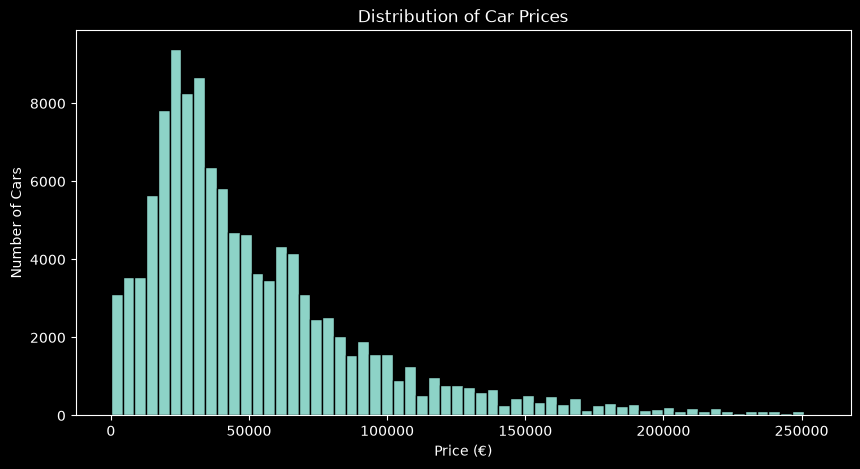

In [12]:
price_limit = df["price"].quantile(0.99)
prices_to_plot = df.loc[df["price"].between(0, price_limit), "price"]

plt.figure(figsize=(10, 5))
plt.hist(prices_to_plot, bins=60, edgecolor="black")

plt.title("Distribution of Car Prices")
plt.xlabel("Price (€)")
plt.ylabel("Number of Cars")

plt.show()

### Price Distribution — Key Findings

- The majority of the cars concentrate on the lower prices and as we can see the peak between 20 and 25 thousand
- Even through we limited the percentil 99 we still have some cars that have a higher values
- The mean price is higher than the median, indicating that expensive vehicles influence the average.

## Vehicle Age Analysis

In [13]:
df[["production_year", "registration_date"]].isna().sum()

production_year      96110
registration_date      221
dtype: int64

96110 do not have the production year so its impossible to use this column to our research

In [14]:
df.loc[
    df["production_year"].notna(),
    ["production_year", "registration_date"]
].head(15)

,production_year,registration_date
16,2025.0,2025-06-01
21,2025.0,2025-01-01
24,2025.0,2025-09-01
25,2019.0,2019-11-01
26,2025.0,2025-02-01
30,2020.0,2020-01-01
38,2024.0,2025-02-01
40,2016.0,2016-06-01
46,2025.0,2025-01-01
47,2025.0,2025-06-01


In [15]:
comparator = df.dropna(subset=["production_year", "registration_date"]).copy()

comparator["registration_year"] = pd.to_datetime(comparator["registration_date"], errors="coerce").dt.year
comparator = comparator.dropna(subset=["registration_year"]).copy()

comparator["year_difference"] = (comparator["registration_year"] - comparator["production_year"]).abs()

print(comparator["year_difference"].describe())
print()
print(comparator["year_difference"].value_counts().sort_index())
print()
print("Difference <= 1 year:", round((comparator["year_difference"] <= 1).mean() * 100, 2), "%")

invalid_years = comparator[comparator["registration_year"] < comparator["production_year"]]

print()
print("Inconsistent records:", len(invalid_years))
print()
print("Percentage:", round(len(invalid_years) / len(comparator) * 100, 2), "%")
print()
print(invalid_years["is_used"].value_counts())

count    22207.000000
mean         0.191021
std          0.519705
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          9.000000
Name: year_difference, dtype: float64

year_difference
0.0    18440
1.0     3554
2.0      130
3.0       37
4.0        8
5.0       13
6.0        1
7.0        1
9.0       23
Name: count, dtype: int64

Difference <= 1 year: 99.04 %

Inconsistent records: 1575

Percentage: 7.09 %

is_used
False    1414
True      161
Name: count, dtype: int64


#### Conclusions

We compared `production_year` and `registration_year` to determine whether the registration year could be used as an alternative for estimating vehicle age.

**Key findings:**

- The `production_year` column contains 96,110 missing values (81.19% of the dataset).
- We compared 22,207 vehicles with both years available.
- Approximately 99.04% of these vehicles have an absolute difference of no more than one year.
- We identified 1,575 records where the registration year is earlier than the reported production year.

**Conclusion:**

The results suggest that `registration_year` is a reasonable approximation for vehicle age in most records where both years are available. However, this does not guarantee the same accuracy for vehicles with missing production years.

The records with conflicting years may contain data errors or differences between the actual manufacturing year and the vehicle's model year.

For now, no records will be removed. These findings will guide our decisions during the data preprocessing stage, where we will define how to handle missing and potentially inconsistent values.

## Mileage Analysis

In [16]:
df["mileage_km"].describe()

count       117738
unique       39809
top       9,900 km
freq          3569
Name: mileage_km, dtype: object

In [17]:
print(df["mileage_km"].dtype)
print(df["mileage_km"].head(10))
print(df["mileage_km"].describe())

str
0     10,500 km
1     55,609 km
2     18,200 km
3         10 km
4     74,602 km
5    200,000 km
6     98,000 km
7        708 km
8    146,000 km
9      7,990 km
Name: mileage_km, dtype: str
count       117738
unique       39809
top       9,900 km
freq          3569
Name: mileage_km, dtype: object


Here we realise that it is not in numbers it is a string so we can convert first and remove km, as we already know that it is in km

In [18]:
mileage_clean = df["mileage_km"].str.replace(" km", "", regex=False).str.replace(",", "", regex=False)

mileage_numeric = pd.to_numeric(mileage_clean, errors="coerce")

In [19]:
print("Original valid values:", df["mileage_km"].notna().sum())
print("Converted values:", mileage_numeric.notna().sum())

print(mileage_numeric.describe().round(2))

Original valid values: 117738
Converted values: 117738
count     117738.00
mean       71676.62
std        70648.60
min            0.00
25%        10000.00
50%        56400.00
75%       111231.75
max      2570000.00
Name: mileage_km, dtype: float64


The mileage_km column was originally stored as text, with values such as 10,500 km. After removing the unit and thousands separators, all 117,738 non-missing values were successfully converted to numbers.

The median mileage is 56,400 km, while the mean is approximately 71,677 km.

The maximum recorded mileage is 2,570,000 km, which is unusually high and requires further investigation before deciding whether it should be excluded.

### Mileage Outlier Investigation

The maximum recorded mileage is 2,570,000 km, which is unusually high.

We will investigate vehicles with extremely high mileage to determine how common these values are and whether they may represent data quality issues.

In [20]:
print("Cars over 500,000 km:", (mileage_numeric > 500000).sum())

display(df.assign(mileage_numeric=mileage_numeric).nlargest(10, "mileage_numeric")[["make", "model", "mileage_numeric", "price", "is_used"]])

Cars over 500,000 km: 20


,make,model,mileage_numeric,price,is_used
15651,BMW,320,2570000.0,5500.0,True
15254,BYD,Atto 3,2424696.0,26990.0,True
7354,Volvo,C30,1560000.0,2000.0,True
64278,BMW,318,1000000.0,500.0,True
77399,BMW,X4 M,900000.0,47500.0,True
29550,Volvo,S60,858890.0,1650.0,True
38452,Volvo,V70,740315.0,2200.0,True
108213,BMW,X5,637525.0,9990.0,True
69704,Volvo,XC70,626349.0,2443.0,True
78921,BMW,740,600000.0,4995.0,True


### Mileage by Vehicle Condition

In [21]:
df.assign(mileage_numeric=mileage_numeric).groupby("is_used")["mileage_numeric"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_used,,,,,,,,
False,22054.0,7000.66,10213.81,0.0,15.00,5697.5,9900.0,204700.0
True,95684.0,86583.64,70222.87,0.0,29449.75,76045.0,125000.0,2570000.0


### Relationship Between Mileage and Price

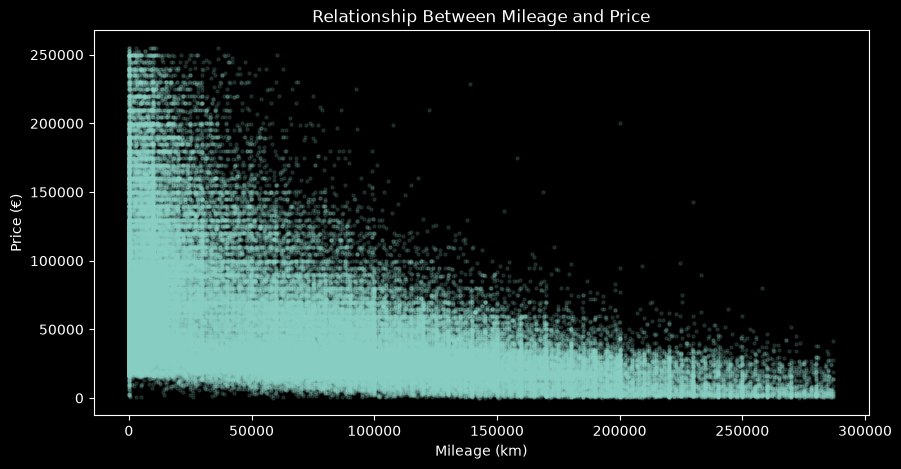

In [22]:
plot_df = df.assign(mileage_numeric=mileage_numeric).dropna(subset=["mileage_numeric", "price"]).copy()

plot_df = plot_df[(plot_df["mileage_numeric"] <= plot_df["mileage_numeric"].quantile(0.99)) & (plot_df["price"] <= plot_df["price"].quantile(0.99))]

plt.figure(figsize=(10, 5))
plt.scatter(plot_df["mileage_numeric"], plot_df["price"], alpha=0.15, s=5)

plt.title("Relationship Between Mileage and Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (€)")

plt.show()

All 117,738 non-missing mileage values were successfully converted from text to numeric values.

The analysis revealed that:

- Only 20 vehicles have more than 500,000 km, including some unusually high values that may indicate data entry errors.
- Used vehicles have a substantially higher median mileage (76,045 km) than vehicles listed as new (5,697.5 km).
- The scatter plot suggests a negative relationship between mileage and price, with higher-priced vehicles becoming less common as mileage increases.

**Conclusion:**

Mileage appears to be a relevant feature for predicting vehicle prices. However, price differences cannot be explained by mileage alone, since other factors such as brand, model, age, and vehicle condition also influence market value.

No extreme mileage records will be removed during this exploratory stage. Potential data quality issues will be addressed during preprocessing.

### Price by Vehicle Condition

We compare the prices of new and used vehicles to investigate whether vehicle condition is associated with differences in market prices.

This analysis will help us evaluate the potential relevance of `is_used` as a feature for our price prediction model.

In [23]:
df.groupby("is_used")["price"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_used,,,,,,,,
False,22698.0,70695.56,58662.52,3999.0,42899.0,59900.0,82908.5,3750000.0
True,95684.0,54389.54,118740.16,1.0,21790.0,34523.5,65900.0,13500000.0


### Key Findings

- New vehicles have a higher median price (€59,900) than used vehicles (€34,523.50).
- The median price difference is approximately €25,377.
- Used vehicles show greater price variability, including some exceptionally expensive listings.

**Conclusion:**

Vehicle condition appears to be associated with market price and may be a useful feature for our prediction model.

However, this comparison does not account for differences in brand, model, age, or other characteristics. Therefore, we cannot attribute the observed price difference solely to vehicle condition.

## Brand and Model Analysis

### Price Distribution by Brand

Vehicle brand is expected to influence market prices, as different manufacturers target different market segments.

We will compare the number of listings and median prices across brands to identify price differences and potential imbalances in the dataset.

In [24]:
brand_stats = df.groupby("make")["price"].agg(["count", "median", "mean"]).round(2)

top_brands = brand_stats.sort_values("count", ascending=False).head(10)

top_brands

,count,median,mean
make,,,
BMW,37745,27900.0,34471.26
Porsche,25511,79560.0,97775.41
Mercedes-Benz,19400,58119.0,70652.29
Audi,15469,60888.0,58888.35
Alfa Romeo,7806,27490.0,26728.06
Suzuki,4592,17790.0,16746.16
Volvo,3643,16660.0,17078.36
Honda,927,11500.0,11807.11
Hyundai,626,8498.5,17258.58


### Price Distribution by Model

Vehicles from the same manufacturer can have significantly different prices depending on their model.

We analyze the 5 most frequently listed models within each of the 10 most represented brands, comparing their number of listings and median prices.

This allows us to identify price differences between models while keeping the analysis concise and easy to interpret.

In [25]:
model_stats = df[df["make"].isin(top_brands.index)].groupby(["make", "model"])["price"].agg(["count", "median"]).round(2)

model_stats.sort_values(["make", "count"], ascending=[True, False]).groupby(level="make").head(5)

count    median
make          model                     
Alfa Romeo    Stelvio     1979   31700.0
              Tonale      1936   29900.0
              Junior       990   29950.0
              Giulia       900   29994.5
              Giulietta    852    9500.0
Aston Martin  Vantage      118   91200.0
              DB9           46   59495.0
              DBX           46  174900.0
              V8            43   79990.0
              Vanquish      31  270000.0
Audi          A6          2003   63490.0
              Q5          1975   64512.0
              Q3          1439   31950.0
              A5          1135   61900.0
              Q8           985   90000.0
BMW           X5          2850   48969.5
              X1          2826   21298.5
              X3          2707   32900.0
              320         2366   22580.0
              118         1892   18900.0
Honda         Civic        287   11490.0
              CR-V         234   12945.0
              Jazz         198    8994.5
              HR-V         100   14340.0
              Accord        50    9450.0
Hyundai       iX35         123   10300.0
              i10          112    6275.0
              i20          102    5895.0
              i30           69    7650.0
              IONIQ 9       65   81190.0
Mercedes-Benz GLC 300      862   72780.0
              GLA 200      836   44023.5
              A 200        745   36990.0
              A 180        724   35622.0
              CLA 250      697   58455.0
Porsche       Cayenne     5697   67000.0
              Macan       4377   55000.0
              992         3090  178900.0
              911         2620  124990.0
              Panamera    2226   66157.5
Suzuki        Swift       1257   15925.0
              Vitara       989   21910.0
              S-Cross      425   24949.0
              Ignis        390   15900.0
              Jimny        336   26800.0
Volvo         XC60         613   22000.0
              XC40         518   23850.0
              V60          470   17900.0
              V40          416    9950.0
              XC90         369   26939.0

### Key Findings

The analysis shows significant price differences across vehicle brands and models.

- BMW, Porsche, Mercedes-Benz, and Audi account for approximately 82.9% of all listings, indicating an imbalanced brand distribution.
- Median prices vary considerably between manufacturers, from €8,498.50 for Hyundai to €117,495 for Aston Martin.
- Different models within the same brand also show substantial price differences. For example, the BMW X5 has a median price of €48,969.50, compared to €21,298.50 for the BMW X1.
- Some brands have relatively few listings, which may affect the model's ability to generalize to less represented manufacturers.

**Conclusion:**

Both `make` and `model` appear to be relevant features for price prediction.

We will retain these features for model development and address their categorical representation during preprocessing. Model performance across different brands should also be considered during evaluation.

## Engine Power Analysis

### Comparing Similar Vehicles

To investigate the relationship between engine power and price, we selected used BMW X5 vehicles.

We focus on vehicles first registered in 2022 to reduce differences related to vehicle age.

Before comparing prices, we will examine the available engine power values and fuel types, since these characteristics may also influence vehicle prices.

In [30]:
x5 = df[(df["make"] == "BMW") & (df["model"] == "X5") & (df["is_used"] == True)].copy()

x5["registration_year"] = pd.to_datetime(x5["registration_date"], errors="coerce").dt.year

x5_2022 = x5[x5["registration_year"] == 2022].copy()

print("BMW X5 registered in 2022:", len(x5_2022))

x5_2022.groupby(["power_hp", "fuel_category"]).size().reset_index(name="cars").sort_values("cars", ascending=False).head(15).reset_index(drop=True)

BMW X5 registered in 2022: 749


,power_hp,fuel_category,cars
0,394.0,Electric/Gasoline,265
1,286.0,Diesel,119
2,286.0,Electric/Gasoline,81
3,340.0,Diesel,81
4,398.0,Electric/Gasoline,34
5,286.0,Electric/Diesel,26
6,340.0,Electric/Diesel,19
7,231.0,Diesel,17
8,290.0,Gasoline,14
9,393.0,Electric/Gasoline,13


### Initial Findings

Among the 749 used BMW X5 vehicles registered in 2022, several engine power and fuel combinations were identified.

For a more controlled comparison, we selected two diesel variants: **286 hp (119 listings)** and **340 hp (81 listings)**.

We will compare their prices and mileage to investigate whether higher engine power is associated with higher vehicle prices.

In [32]:
diesel_x5 = x5_2022[(x5_2022["fuel_category"] == "Diesel") & (x5_2022["power_hp"].isin([286, 340]))].copy()

diesel_x5["mileage_numeric"] = mileage_numeric.loc[diesel_x5.index]

diesel_x5.groupby("power_hp").agg(
    cars=("power_hp", "size"),
    median_price=("price", "median"),
    median_mileage=("mileage_numeric", "median")
).round(2)

,cars,median_price,median_mileage
power_hp,,,
286.0,119,56790.0,74820.0
340.0,81,63990.0,74741.0


### Engine Power Analysis — Key Findings

We compared two groups of used BMW X5 diesel vehicles registered in 2022, with different engine power levels.

- **286 hp:** 119 listings, with a median price of 56,790€ and median mileage of 74,820 km.
- **340 hp:** 81 listings, with a median price of 63,990€ and median mileage of 74,741 km.

The 340 hp vehicles have a median price 7,200€ higher, while the median mileage differs by only 79 km.

**Conclusion:**

This comparison suggests that engine power is associated with vehicle price, even when considering vehicles with the same brand, model, registration year, fuel category, and similar median mileage.

We will retain `power_hp` as a potential feature for our prediction model.